# Exploratory Data Analysis for Stock Return Prediction

This notebook studies the data coverage, target distribution, cross-sectional structure, feature quality, and time variation of the dataset used for machine-learning-based stock return prediction. The goal is to motivate the later rolling-window LightGBM modeling and long-short portfolio experiment.


## 1. Setup and Data Preparation

This section loads the source dataset, constructs the forward-return targets if needed, identifies feature columns, and summarizes the basic shape of the EDA sample.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from scipy import stats
except Exception:
    stats = None

plt.style.use("default")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)


In [2]:
# Fallback data preparation for standalone execution.
def _eda_make_price_panel(raw_data, requested_universe):
    frames = []
    valid_tickers = []

    for ticker in requested_universe:
        try:
            px = raw_data[ticker].copy()
        except Exception:
            continue

        if px.empty or "Close" not in px.columns or px["Close"].dropna().empty:
            continue

        keep_cols = [c for c in ["Open", "High", "Low", "Close", "Volume"] if c in px.columns]
        px = px[keep_cols].copy()
        px["code"] = ticker
        frames.append(px.reset_index().rename(columns={"Date": "date"}))
        valid_tickers.append(ticker)

    if not frames:
        raise ValueError("No valid tickers were downloaded. Check the data source or network connection.")

    out = pd.concat(frames, ignore_index=True)
    out["date"] = pd.to_datetime(out["date"])
    out = out.sort_values(["code", "date"]).reset_index(drop=True)
    price_cols = ["Open", "High", "Low", "Close"]
    out[price_cols] = out.groupby("code")[price_cols].ffill()
    out["Volume"] = out.groupby("code")["Volume"].transform(lambda x: x.fillna(0))
    out["Return"] = out.groupby("code")["Close"].pct_change()
    out = out.dropna(subset=price_cols + ["Return"]).reset_index(drop=True)
    return out, valid_tickers


def _eda_add_technical_features(df_in):
    df_local = df_in.sort_values(["code", "date"]).reset_index(drop=True).copy()
    g = df_local.groupby("code", group_keys=False)
    f = pd.DataFrame(index=df_local.index)

    f["open_1"] = g["Open"].shift(1)
    f["high_1"] = g["High"].shift(1)
    f["low_1"] = g["Low"].shift(1)
    f["close_1"] = g["Close"].shift(1)
    f["close_2"] = g["Close"].shift(2)
    f["volume_1"] = g["Volume"].shift(1)
    f["log_volume_1"] = np.log1p(f["volume_1"])

    f["overnight_gap_1"] = f["open_1"] / f["close_2"] - 1
    f["intraday_return_1"] = f["close_1"] / f["open_1"] - 1
    f["high_low_range_1"] = f["high_1"] / f["low_1"] - 1
    f["close_position_1"] = (f["close_1"] - f["low_1"]) / (f["high_1"] - f["low_1"]).replace(0, np.nan)

    for window in [1, 2, 5, 10, 20, 60, 120, 250]:
        f[f"return_{window}"] = g["Close"].transform(lambda x, w=window: (x / x.shift(w) - 1).shift(1))
    for window in [1, 5, 20, 60, 250]:
        f[f"log_return_{window}"] = g["Close"].transform(lambda x, w=window: np.log(x).diff(w).shift(1))

    f["momentum_20_minus_5"] = f["return_20"] - f["return_5"]
    f["momentum_60_minus_20"] = f["return_60"] - f["return_20"]
    f["momentum_250_minus_60"] = f["return_250"] - f["return_60"]

    for window in [5, 20, 60, 250]:
        f[f"ret_mean_{window}"] = g["Close"].transform(lambda x, w=window: x.pct_change().rolling(w).mean().shift(1))
        f[f"ret_std_{window}"] = g["Close"].transform(lambda x, w=window: x.pct_change().rolling(w).std().shift(1))

    ma = {}
    for window in [5, 10, 20, 60, 120, 250]:
        ma[window] = g["Close"].transform(lambda x, w=window: x.rolling(w).mean().shift(1))
        f[f"close_to_ma_{window}"] = f["close_1"] / ma[window] - 1

    f["ma_5_to_20"] = ma[5] / ma[20] - 1
    f["ma_20_to_60"] = ma[20] / ma[60] - 1
    f["ma_60_to_250"] = ma[60] / ma[250] - 1

    for window in [20, 60]:
        price_std = g["Close"].transform(lambda x, w=window: x.rolling(w).std().shift(1))
        f[f"bollinger_z_{window}"] = (f["close_1"] - ma[window]) / price_std

    prev_close = g["Close"].shift(1)
    true_range = pd.concat([
        df_local["High"] - df_local["Low"],
        (df_local["High"] - prev_close).abs(),
        (df_local["Low"] - prev_close).abs(),
    ], axis=1).max(axis=1)
    tr_df = pd.DataFrame({"code": df_local["code"], "true_range": true_range})
    tr_g = tr_df.groupby("code", group_keys=False)
    for window in [14, 20, 60]:
        f[f"natr_{window}"] = tr_g["true_range"].transform(lambda x, w=window: x.rolling(w).mean().shift(1)) / f["close_1"]

    def _eda_rsi(x, window):
        diff = x.diff()
        gain = diff.clip(lower=0).rolling(window).mean()
        loss = (-diff.clip(upper=0)).rolling(window).mean()
        return (100 - 100 / (1 + gain / loss)).shift(1)

    f["rsi_14"] = g["Close"].transform(lambda x: _eda_rsi(x, 14))
    f["rsi_28"] = g["Close"].transform(lambda x: _eda_rsi(x, 28))
    f["ema_12_to_26"] = g["Close"].transform(lambda x: (x.ewm(span=12, adjust=False).mean() / x.ewm(span=26, adjust=False).mean() - 1).shift(1))
    f["ema_20_to_60"] = g["Close"].transform(lambda x: (x.ewm(span=20, adjust=False).mean() / x.ewm(span=60, adjust=False).mean() - 1).shift(1))

    for window in [1, 5, 20]:
        f[f"volume_log_change_{window}"] = g["Volume"].transform(lambda x, w=window: np.log1p(x).diff(w).shift(1))

    log_volume = np.log1p(df_local["Volume"])
    lv_df = pd.DataFrame({"code": df_local["code"], "log_volume": log_volume})
    lv_g = lv_df.groupby("code", group_keys=False)
    for window in [20, 60]:
        lv_mean = lv_g["log_volume"].transform(lambda x, w=window: x.rolling(w).mean().shift(1))
        lv_std = lv_g["log_volume"].transform(lambda x, w=window: x.rolling(w).std().shift(1))
        f[f"relative_log_volume_{window}"] = f["log_volume_1"] - lv_mean
        f[f"volume_zscore_{window}"] = (f["log_volume_1"] - lv_mean) / lv_std

    dollar_volume = df_local["Close"] * df_local["Volume"]
    dv_df = pd.DataFrame({"code": df_local["code"], "dollar_volume": dollar_volume})
    dv_g = dv_df.groupby("code", group_keys=False)
    for window in [1, 5, 20]:
        f[f"dollar_volume_log_change_{window}"] = dv_g["dollar_volume"].transform(lambda x, w=window: np.log1p(x).diff(w).shift(1))

    cs_base = pd.concat([df_local[["date"]], f], axis=1)
    for col in ["return_1", "return_5", "return_20", "return_60", "ret_std_20", "ret_std_60", "volume_zscore_20", "close_to_ma_20"]:
        if col in cs_base.columns:
            f[f"{col}_cs_rank"] = cs_base.groupby("date")[col].rank(pct=True)

    f["day_of_week"] = df_local["date"].dt.dayofweek
    f["month"] = df_local["date"].dt.month
    f["quarter"] = df_local["date"].dt.quarter
    f["is_month_start"] = df_local["date"].dt.is_month_start.astype(int)
    f["is_month_end"] = df_local["date"].dt.is_month_end.astype(int)

    out = pd.concat([df_local, f], axis=1)
    return out.replace([np.inf, -np.inf], np.nan)


def _eda_build_standalone_source_df():
    import yfinance as yf

    universe = [
        "NVDA", "AMD", "INTC", "QCOM", "AVGO", "TXN", "MU", "ADI",
        "MRVL", "MCHP", "MPWR", "ON", "NXPI", "SWKS", "QRVO",
        "LSCC", "CRUS", "DIOD", "POWI", "ALGM",
        "AMAT", "LRCX", "KLAC", "TER", "ENTG", "ACLS", "AEHR",
        "ASML", "ASX", "UCTT", "FORM", "COHR",
        "TSM", "UMC", "STM", "GFS",
        "SNPS", "CDNS", "ANSS",
        "AAPL", "MSFT", "GOOGL", "META", "AMZN",
        "DELL", "HPQ", "SMCI", "HPE", "ARW", "AVT",
    ]
    raw_data = yf.download(
        universe,
        start="2010-01-01",
        end="2022-12-31",
        auto_adjust=True,
        progress=True,
        group_by="ticker",
        threads=True,
    )
    base_df, _ = _eda_make_price_panel(raw_data, universe)
    feature_df = _eda_add_technical_features(base_df)
    feature_df["target_5d"] = feature_df.groupby("code")["Close"].shift(-5) / feature_df["Close"] - 1
    base_cols = ["date", "code", "Open", "High", "Low", "Close", "Volume", "Return", "target_5d"]
    feature_cols = [c for c in feature_df.columns if c not in base_cols]
    return feature_df.dropna(subset=feature_cols + ["target_5d"]).copy().reset_index(drop=True)


In [3]:
if "rolling5y_source_df" in globals():
    _eda_source_name = "rolling5y_source_df"
    _eda_source_df = rolling5y_source_df
elif "walk_forward_model_df" in globals():
    _eda_source_name = "walk_forward_model_df"
    _eda_source_df = walk_forward_model_df
elif "df_model" in globals():
    _eda_source_name = "df_model"
    _eda_source_df = df_model
elif "df" in globals():
    _eda_source_name = "df"
    _eda_source_df = df
else:
    _eda_source_name = "standalone_download"
    _eda_source_df = _eda_build_standalone_source_df()

eda_start_date = pd.Timestamp("2010-01-01")
eda_end_date = pd.Timestamp("2022-12-31")

eda_df = _eda_source_df.copy()
eda_df["date"] = pd.to_datetime(eda_df["date"])
eda_df = eda_df.sort_values(["date", "code"]).reset_index(drop=True)
eda_df = eda_df[eda_df["date"].between(eda_start_date, eda_end_date)].copy().reset_index(drop=True)

if "target_5d_raw" not in eda_df.columns:
    eda_df["target_5d_raw"] = eda_df.groupby("code")["Close"].shift(-5) / eda_df["Close"] - 1
if "target_5d_cs" not in eda_df.columns:
    eda_df["target_5d_cs"] = eda_df["target_5d_raw"] - eda_df.groupby("date")["target_5d_raw"].transform("mean")

eda_exclude_cols = {
    "date", "code", "Open", "High", "Low", "Close", "Volume", "Return",
    "target_5d", "target_5d_raw", "target_5d_cs",
}
eda_feature_cols = [c for c in eda_df.columns if c not in eda_exclude_cols]

eda_df = eda_df.dropna(subset=["target_5d_raw", "target_5d_cs"]).copy().reset_index(drop=True)
eda_df["year"] = eda_df["date"].dt.year

eda_basic_info_df = pd.DataFrame([
    {
        "source_dataframe": _eda_source_name,
        "num_rows": len(eda_df),
        "num_columns": eda_df.shape[1],
        "date_min": eda_df["date"].min(),
        "date_max": eda_df["date"].max(),
        "num_stocks": eda_df["code"].nunique(),
        "num_features": len(eda_feature_cols),
    }
])

print(eda_df.shape)
print(eda_df["date"].min(), eda_df["date"].max())
print("Number of stocks:", eda_df["code"].nunique())
print("Number of features:", len(eda_feature_cols))
display(eda_basic_info_df)


[*****************     36%                       ]  18 of 50 completedERROR:yfinance:HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ANSS"}}}
[*********************100%***********************]  50 of 50 completed
ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['ANSS']: YFTzMissingError('possibly delisted; no timezone found')
/tmp/ipykernel_3570/984581304.py:30: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  out["Return"] = out.groupby("code")["Close"].pct_change()


(136529, 88)
2011-01-03 00:00:00 2022-12-15 00:00:00
Number of stocks: 49
Number of features: 76


,source_dataframe,num_rows,num_columns,date_min,date_max,num_stocks,num_features
0,standalone_download,136529,88,2011-01-03,2022-12-15,49,76


## 2. Data Coverage and Stock Universe

The stock universe can be mildly unbalanced because some names start later or have gaps. Coverage diagnostics help verify that each rolling window has enough names and observations for cross-sectional analysis.


In [4]:
eda_dates_per_year = (
    eda_df.groupby(["year", "date"])["code"]
    .nunique()
    .rename("stocks_per_date")
    .reset_index()
)

eda_yearly_coverage_df = (
    eda_dates_per_year.groupby("year")
    .agg(
        num_dates=("date", "nunique"),
        avg_stocks_per_date=("stocks_per_date", "mean"),
        min_stocks_per_date=("stocks_per_date", "min"),
        max_stocks_per_date=("stocks_per_date", "max"),
    )
    .reset_index()
)
eda_yearly_rows = eda_df.groupby("year").size().rename("num_rows").reset_index()
eda_yearly_coverage_df = eda_yearly_coverage_df.merge(eda_yearly_rows, on="year", how="left")
eda_yearly_coverage_df["num_stocks"] = eda_df.groupby("year")["code"].nunique().values
eda_yearly_coverage_df = eda_yearly_coverage_df[[
    "year", "num_rows", "num_dates", "num_stocks", "avg_stocks_per_date", "min_stocks_per_date", "max_stocks_per_date"
]]

eda_stock_coverage_df = (
    eda_df.groupby("code")
    .agg(
        first_date=("date", "min"),
        last_date=("date", "max"),
        num_rows=("date", "size"),
        num_dates=("date", "nunique"),
    )
    .reset_index()
    .sort_values(["first_date", "code"])
    .reset_index(drop=True)
)

eda_missing_feature_mask = eda_df[eda_feature_cols].isna().any(axis=1)
eda_missing_by_year_df = (
    eda_df.assign(rows_with_any_feature_missing=eda_missing_feature_mask)
    .groupby("year")
    .agg(
        total_rows=("date", "size"),
        rows_with_any_feature_missing=("rows_with_any_feature_missing", "sum"),
    )
    .reset_index()
)
eda_missing_by_year_df["missing_feature_row_ratio"] = (
    eda_missing_by_year_df["rows_with_any_feature_missing"] / eda_missing_by_year_df["total_rows"]
)

display(eda_yearly_coverage_df)
display(eda_stock_coverage_df)
display(eda_missing_by_year_df)


,year,num_rows,num_dates,num_stocks,avg_stocks_per_date,min_stocks_per_date,max_stocks_per_date
0,2011,10670,252,43,42.341270,42,43
1,2012,10697,250,43,42.788000,42,43
2,2013,10963,252,44,43.503968,42,44
3,2014,11082,252,44,43.976190,43,44
4,2015,11075,252,44,43.948413,43,44
5,2016,11383,252,46,45.170635,44,46
6,2017,11640,251,47,46.374502,46,47
7,2018,11795,251,47,46.992032,46,47
8,2019,11843,252,47,46.996032,46,47
9,2020,11891,253,47,47.000000,47,47


,code,first_date,last_date,num_rows,num_dates
0,AAPL,2011-01-03,2022-12-15,3010,3010
1,ACLS,2011-01-03,2022-12-15,3010,3010
2,ADI,2011-01-03,2022-12-15,3010,3010
3,AEHR,2011-01-03,2022-12-15,2886,2886
4,AMAT,2011-01-03,2022-12-15,3010,3010
5,AMD,2011-01-03,2022-12-15,3009,3009
6,AMZN,2011-01-03,2022-12-15,3010,3010
7,ARW,2011-01-03,2022-12-15,3010,3010
8,ASML,2011-01-03,2022-12-15,3010,3010
9,ASX,2011-01-03,2022-12-15,3008,3008


,year,total_rows,rows_with_any_feature_missing,missing_feature_row_ratio
0,2011,10670,0,0.0
1,2012,10697,0,0.0
2,2013,10963,0,0.0
3,2014,11082,0,0.0
4,2015,11075,0,0.0
5,2016,11383,0,0.0
6,2017,11640,0,0.0
7,2018,11795,0,0.0
8,2019,11843,0,0.0
9,2020,11891,0,0.0


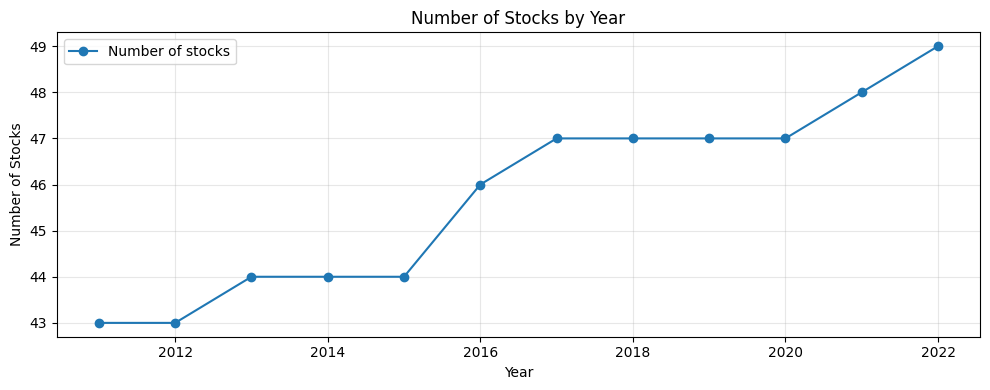

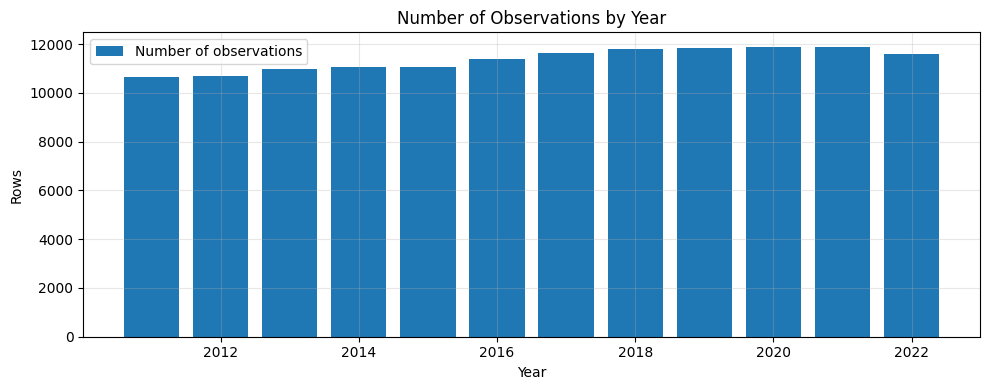

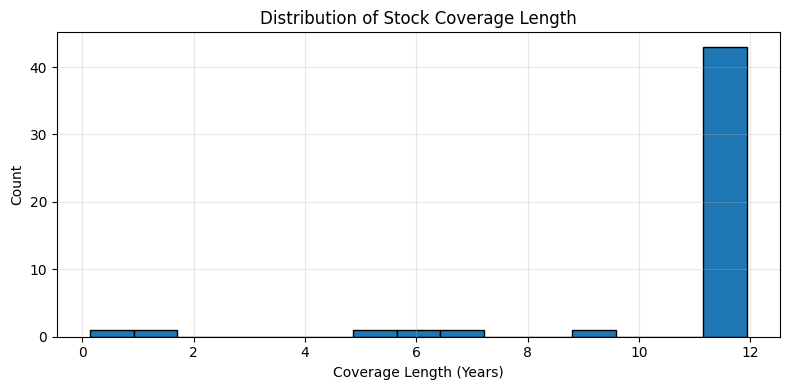

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(eda_yearly_coverage_df["year"], eda_yearly_coverage_df["num_stocks"], marker="o", label="Number of stocks")
ax.set_title("Number of Stocks by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Stocks")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(eda_yearly_coverage_df["year"], eda_yearly_coverage_df["num_rows"], label="Number of observations")
ax.set_title("Number of Observations by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Rows")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

eda_stock_coverage_df["coverage_years"] = (
    (eda_stock_coverage_df["last_date"] - eda_stock_coverage_df["first_date"]).dt.days / 365.25
)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(eda_stock_coverage_df["coverage_years"].dropna(), bins=15, edgecolor="black")
ax.set_title("Distribution of Stock Coverage Length")
ax.set_xlabel("Coverage Length (Years)")
ax.set_ylabel("Count")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Coverage appears to be driven by a mostly stable universe with some entry timing differences across names. The panel is therefore not perfectly balanced, but it is typically only mildly unbalanced rather than severely fragmented.

These diagnostics matter because rolling-window evaluation depends on consistent cross-sectional breadth. If the number of names changed sharply across periods, later model comparisons could be confounded by sample-composition effects rather than signal quality.


## 3. Target Construction and Distribution

The raw target is defined as `target_5d_raw = Close_{t+5} / Close_t - 1`. The cross-sectionally demeaned target is `target_5d_cs = target_5d_raw - same-date average target_5d_raw`.

The later ML model will predict the cross-sectional target because the long-short strategy is based on ranking stocks relative to each other, not forecasting market direction alone.


In [6]:
def _eda_series_skew(x):
    s = pd.Series(x).dropna()
    if len(s) < 3:
        return np.nan
    if stats is not None:
        return stats.skew(s, bias=False, nan_policy="omit")
    return s.skew()


def _eda_series_kurtosis(x):
    s = pd.Series(x).dropna()
    if len(s) < 4:
        return np.nan
    if stats is not None:
        return stats.kurtosis(s, fisher=True, bias=False, nan_policy="omit")
    return s.kurt()


eda_target_summary_df = eda_df[["target_5d_raw", "target_5d_cs"]].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

eda_target_by_year_df = (
    eda_df.groupby("year")
    .agg(
        raw_target_mean=("target_5d_raw", "mean"),
        raw_target_std=("target_5d_raw", "std"),
        cs_target_mean=("target_5d_cs", "mean"),
        cs_target_std=("target_5d_cs", "std"),
    )
    .reset_index()
)
eda_target_by_year_df["raw_target_skew"] = eda_df.groupby("year")["target_5d_raw"].apply(_eda_series_skew).values
eda_target_by_year_df["raw_target_kurtosis"] = eda_df.groupby("year")["target_5d_raw"].apply(_eda_series_kurtosis).values
eda_target_by_year_df["cs_target_skew"] = eda_df.groupby("year")["target_5d_cs"].apply(_eda_series_skew).values
eda_target_by_year_df["cs_target_kurtosis"] = eda_df.groupby("year")["target_5d_cs"].apply(_eda_series_kurtosis).values

display(eda_target_summary_df)
display(eda_target_by_year_df)


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
target_5d_raw,136529.0,4.573998e-03,0.055592,-0.439283,-0.140933,-0.081218,-0.023585,0.004663,0.031741,0.088755,0.160166,1.837456
target_5d_cs,136529.0,-3.395016e-20,0.042053,-0.426800,-0.108019,-0.058025,-0.020081,-0.001356,0.018068,0.061080,0.124587,1.791825


,year,raw_target_mean,raw_target_std,cs_target_mean,cs_target_std,raw_target_skew,raw_target_kurtosis,cs_target_skew,cs_target_kurtosis
0,2011,-0.000207,0.064884,-3.459692e-19,0.045119,0.207652,2.327477,0.239222,6.085462
1,2012,0.002114,0.051237,7.784120e-21,0.041091,0.621169,7.102611,0.994382,14.535689
2,2013,0.007706,0.046780,-2.316551e-19,0.042446,1.683626,19.270524,2.206133,26.901529
3,2014,0.004716,0.044634,-1.202191e-19,0.035640,0.162135,5.057680,0.644790,8.622277
4,2015,0.000198,0.049112,-1.253073e-20,0.040391,0.165011,3.611326,0.385923,7.410700
5,2016,0.008403,0.051033,-1.557487e-19,0.042462,1.362795,13.904101,2.368033,25.912637
6,2017,0.007977,0.043817,-3.695974e-20,0.038279,1.238448,21.024575,1.837688,32.482739
7,2018,-0.002701,0.054530,-7.294810e-20,0.040834,-0.158236,3.470672,-0.098952,7.315171
8,2019,0.011162,0.049375,1.371022e-19,0.038958,0.765043,7.508081,1.400726,15.694920
9,2020,0.010752,0.070719,2.672621e-19,0.046076,0.058315,4.055065,0.657620,6.653214


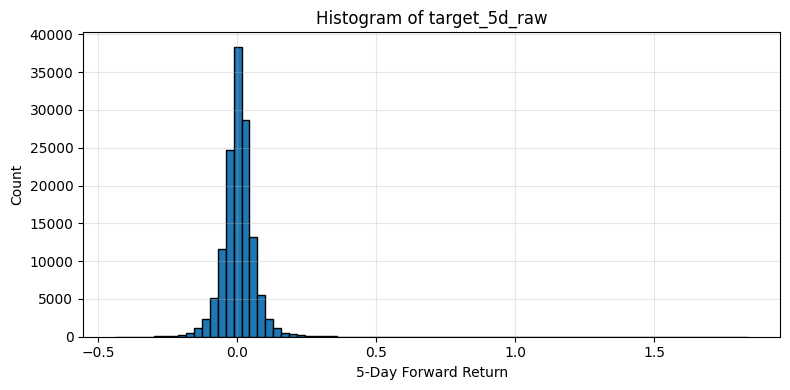

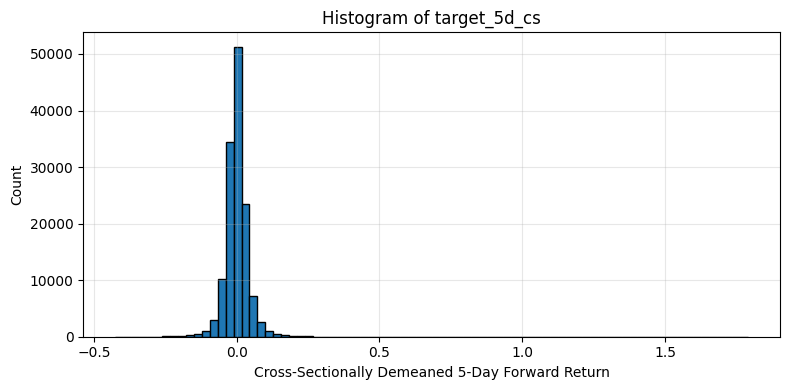

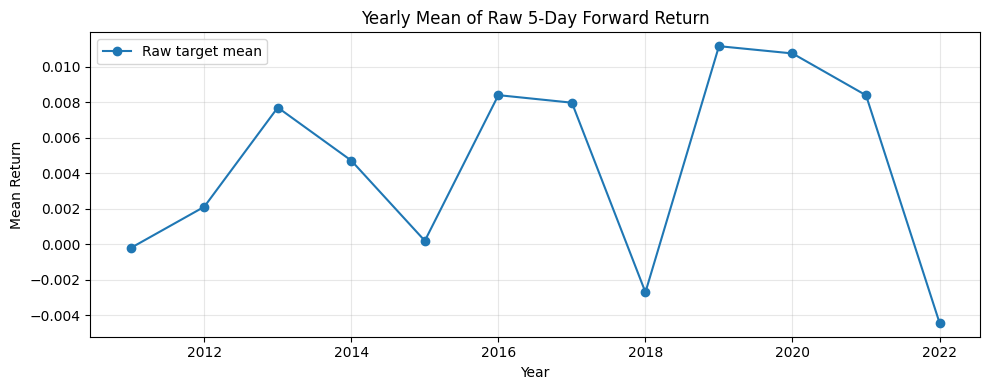

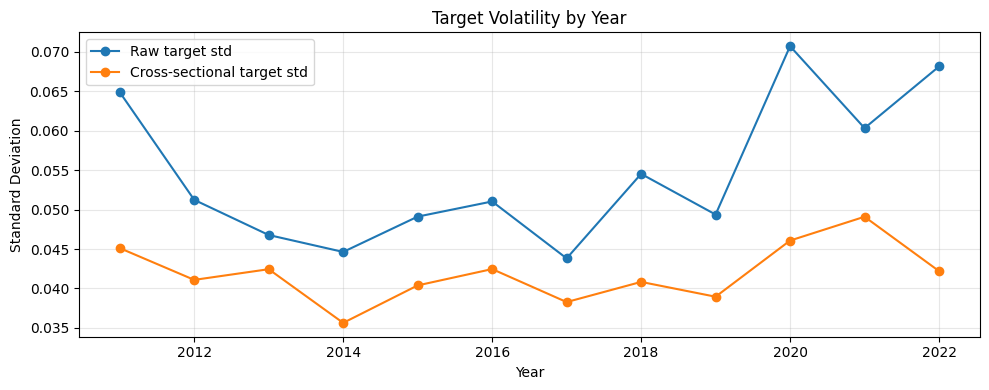

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(eda_df["target_5d_raw"].dropna(), bins=80, edgecolor="black")
ax.set_title("Histogram of target_5d_raw")
ax.set_xlabel("5-Day Forward Return")
ax.set_ylabel("Count")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(eda_df["target_5d_cs"].dropna(), bins=80, edgecolor="black")
ax.set_title("Histogram of target_5d_cs")
ax.set_xlabel("Cross-Sectionally Demeaned 5-Day Forward Return")
ax.set_ylabel("Count")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(eda_target_by_year_df["year"], eda_target_by_year_df["raw_target_mean"], marker="o", label="Raw target mean")
ax.set_title("Yearly Mean of Raw 5-Day Forward Return")
ax.set_xlabel("Year")
ax.set_ylabel("Mean Return")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(eda_target_by_year_df["year"], eda_target_by_year_df["raw_target_std"], marker="o", label="Raw target std")
ax.plot(eda_target_by_year_df["year"], eda_target_by_year_df["cs_target_std"], marker="o", label="Cross-sectional target std")
ax.set_title("Target Volatility by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Standard Deviation")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


Raw forward returns include market-wide movement, while cross-sectional demeaning removes the same-date common component and leaves a more ranking-oriented target. Both targets remain noisy, and their distributions are typically heavy-tailed rather than well-behaved Gaussian variables.

The year-by-year volatility variation also indicates non-stationarity. That is one reason the later experiment uses rolling-window evaluation instead of assuming a single stable return regime across the full sample.


## 4. Cross-Sectional Return Structure

The later strategy is cross-sectional, so the amount of dispersion across stocks on each date matters for how much separation a ranking model can potentially exploit.


In [8]:
eda_daily_cross_section_df = (
    eda_df.groupby("date")
    .agg(
        num_stocks=("code", "nunique"),
        raw_return_mean=("target_5d_raw", "mean"),
        raw_return_std=("target_5d_raw", "std"),
        raw_return_median=("target_5d_raw", "median"),
        cs_return_mean=("target_5d_cs", "mean"),
        cs_return_std=("target_5d_cs", "std"),
        cs_return_median=("target_5d_cs", "median"),
    )
    .reset_index()
)

eda_cross_section_summary_df = eda_daily_cross_section_df[["num_stocks", "raw_return_std", "cs_return_std"]].describe()

display(eda_daily_cross_section_df)
display(eda_cross_section_summary_df)


,date,num_stocks,raw_return_mean,raw_return_std,raw_return_median,cs_return_mean,cs_return_std,cs_return_median
0,2011-01-03,42,0.019144,0.066114,0.004042,0.000000e+00,0.066114,-0.015102
1,2011-01-04,42,0.028910,0.052802,0.018776,3.386841e-18,0.052802,-0.010134
2,2011-01-05,42,0.047510,0.066268,0.033116,-2.643388e-18,0.066268,-0.014394
3,2011-01-06,42,0.044511,0.063525,0.028330,-2.478176e-18,0.063525,-0.016181
4,2011-01-07,42,0.063271,0.069087,0.052649,-2.312965e-18,0.069087,-0.010623
...,...,...,...,...,...,...,...,...
3005,2022-12-09,49,-0.029474,0.023560,-0.028025,-2.194956e-18,0.023560,0.001449
3006,2022-12-12,49,-0.063815,0.025754,-0.062298,-5.947623e-18,0.025754,0.001517
3007,2022-12-13,49,-0.078970,0.025775,-0.079568,-2.832202e-18,0.025775,-0.000598
3008,2022-12-14,49,-0.046156,0.025653,-0.046734,-2.832202e-18,0.025653,-0.000578


,num_stocks,raw_return_std,cs_return_std
count,3010.000000,3010.000000,3010.000000
mean,45.358472,0.040101,0.040101
std,1.927759,0.014085,0.014085
min,42.000000,0.015550,0.015550
25%,44.000000,0.030901,0.030901
50%,46.000000,0.037506,0.037506
75%,47.000000,0.046673,0.046673
max,49.000000,0.268073,0.268073


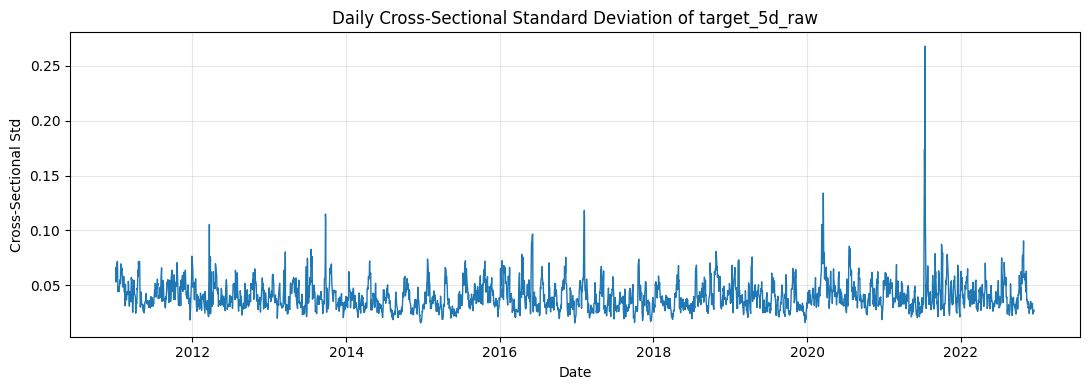

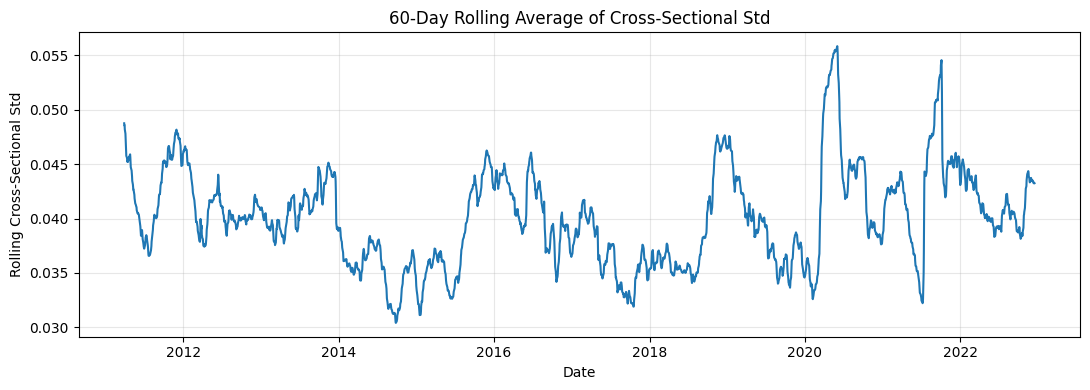

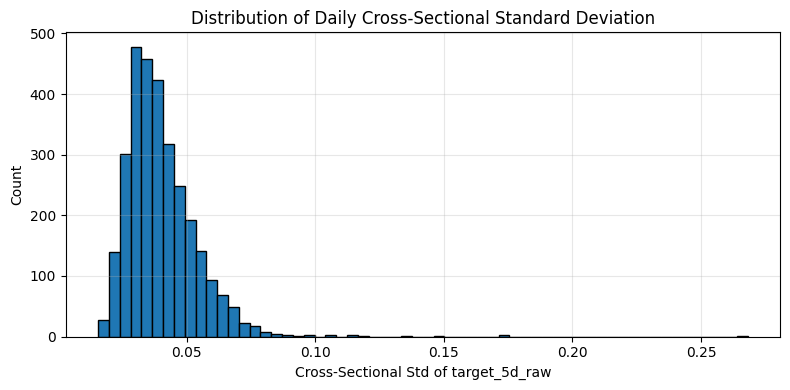

In [9]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(eda_daily_cross_section_df["date"], eda_daily_cross_section_df["raw_return_std"], linewidth=1)
ax.set_title("Daily Cross-Sectional Standard Deviation of target_5d_raw")
ax.set_xlabel("Date")
ax.set_ylabel("Cross-Sectional Std")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    eda_daily_cross_section_df["date"],
    eda_daily_cross_section_df["raw_return_std"].rolling(60).mean(),
    linewidth=1.5,
)
ax.set_title("60-Day Rolling Average of Cross-Sectional Std")
ax.set_xlabel("Date")
ax.set_ylabel("Rolling Cross-Sectional Std")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(eda_daily_cross_section_df["raw_return_std"].dropna(), bins=60, edgecolor="black")
ax.set_title("Distribution of Daily Cross-Sectional Standard Deviation")
ax.set_xlabel("Cross-Sectional Std of target_5d_raw")
ax.set_ylabel("Count")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Higher cross-sectional dispersion creates more opportunity for ranking-based long-short strategies because there is more separation between winners and losers on a given date. The dispersion is not constant over time, so the later model should be judged in a rolling framework rather than on a single pooled regime.


## 5. Feature Overview and Missingness

The feature set is composed mainly of price-based returns and momentum signals, volatility measures, volume and liquidity proxies, and technical indicators derived from rolling windows.


In [10]:
def eda_categorize_feature(feature_name):
    name = feature_name.lower()
    if any(token in name for token in ["return", "momentum", "ret"]):
        return "return/momentum"
    if any(token in name for token in ["volatility", "vol", "std", "risk"]):
        return "volatility/risk"
    if any(token in name for token in ["volume", "dollar", "turnover", "liquidity"]):
        return "volume/liquidity"
    if any(token in name for token in ["rsi", "macd", "bb", "bollinger", "ma", "ema", "sma"]):
        return "technical indicators"
    return "other"


eda_feature_groups_df = (
    pd.DataFrame({"feature": eda_feature_cols})
    .assign(feature_group=lambda x: x["feature"].map(eda_categorize_feature))
    .groupby("feature_group")
    .agg(
        num_features=("feature", "size"),
        example_features=("feature", lambda x: ", ".join(list(x[:5]))),
    )
    .reset_index()
    .sort_values("num_features", ascending=False)
    .reset_index(drop=True)
)

eda_feature_missing_df = pd.DataFrame({"feature": eda_feature_cols})
eda_feature_missing_df["missing_ratio"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].isna().mean())
eda_feature_missing_df["mean"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].mean())
eda_feature_missing_df["std"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].std())
eda_feature_missing_df["min"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].min())
eda_feature_missing_df["p01"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].quantile(0.01))
eda_feature_missing_df["p05"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].quantile(0.05))
eda_feature_missing_df["median"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].median())
eda_feature_missing_df["p95"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].quantile(0.95))
eda_feature_missing_df["p99"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].quantile(0.99))
eda_feature_missing_df["max"] = eda_feature_missing_df["feature"].map(lambda c: eda_df[c].max())
eda_feature_missing_df = eda_feature_missing_df.sort_values("missing_ratio", ascending=False).reset_index(drop=True)

display(eda_feature_groups_df)
display(eda_feature_missing_df.head(20))


,feature_group,num_features,example_features
0,return/momentum,31,"intraday_return_1, return_1, return_2, return_..."
1,other,16,"open_1, high_1, low_1, close_1, close_2"
2,technical indicators,16,"close_to_ma_5, close_to_ma_10, close_to_ma_20,..."
3,volatility/risk,13,"volume_1, log_volume_1, volume_log_change_1, v..."


,feature,missing_ratio,mean,std,min,p01,p05,median,p95,p99,max
0,open_1,0.0,4.573803e+01,6.473862e+01,2.637267e-01,0.791754,2.066998,2.522840e+01,1.529986e+02,3.270648e+02,8.473549e+02
1,high_1,0.0,4.635113e+01,6.559737e+01,2.662448e-01,0.808104,2.111824,2.556000e+01,1.551464e+02,3.317443e+02,8.558953e+02
2,low_1,0.0,4.510303e+01,6.382382e+01,2.552562e-01,0.770000,2.030000,2.487161e+01,1.507599e+02,3.230316e+02,8.403714e+02
3,close_1,0.0,4.574148e+01,6.474026e+01,2.605216e-01,0.793919,2.070000,2.522667e+01,1.528837e+02,3.273953e+02,8.495904e+02
4,close_2,0.0,4.571281e+01,6.470620e+01,2.605216e-01,0.793919,2.070000,2.520874e+01,1.528484e+02,3.271575e+02,8.495904e+02
5,volume_1,0.0,2.684482e+07,9.628100e+07,0.000000e+00,31028.000000,179300.000000,3.225000e+06,9.868313e+07,4.998558e+08,3.692928e+09
6,log_volume_1,0.0,1.507590e+01,2.052771e+00,0.000000e+00,10.342676,12.096821,1.498644e+01,1.840742e+01,2.002983e+01,2.202969e+01
7,overnight_gap_1,0.0,6.225001e-04,1.514844e-02,-3.048129e-01,-0.040875,-0.019273,5.417743e-04,1.990757e-02,4.342809e-02,4.499999e-01
8,intraday_return_1,0.0,3.484405e-04,2.089806e-02,-2.531646e-01,-0.055556,-0.031507,1.774010e-04,3.151614e-02,5.905339e-02,4.761029e-01
9,high_low_range_1,0.0,2.952060e-02,2.210717e-02,1.123230e-03,0.007092,0.010042,2.409321e-02,6.585347e-02,1.095498e-01,1.736000e+00


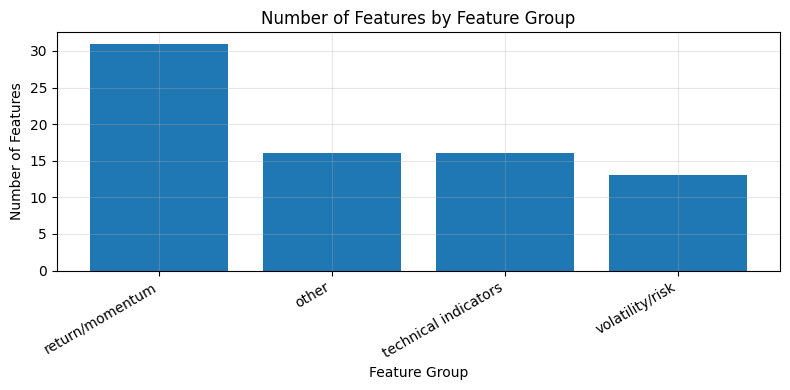

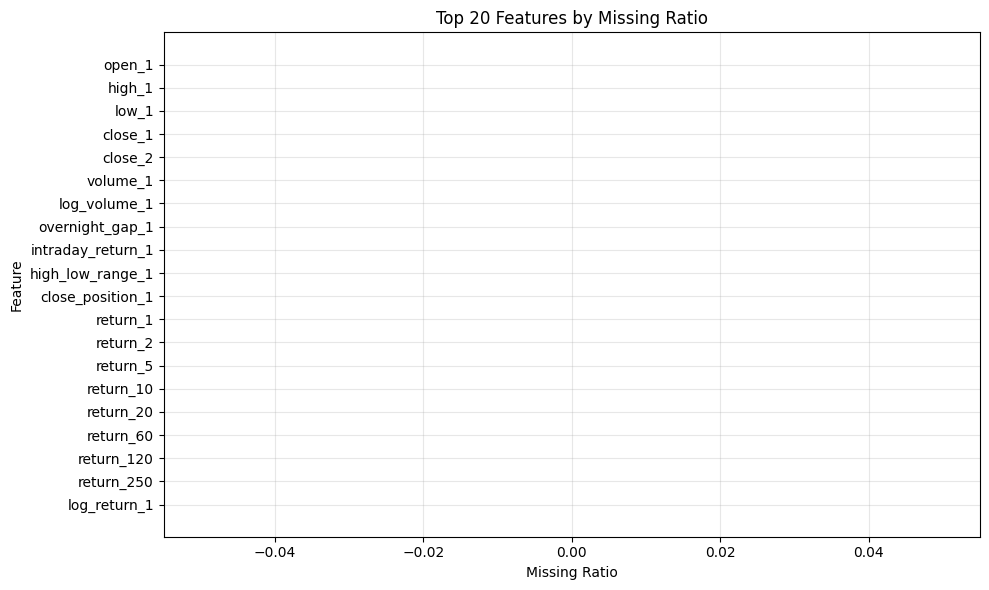

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(eda_feature_groups_df["feature_group"], eda_feature_groups_df["num_features"])
ax.set_title("Number of Features by Feature Group")
ax.set_xlabel("Feature Group")
ax.set_ylabel("Number of Features")
ax.grid(True, alpha=0.3)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

eda_top_missing_df = eda_feature_missing_df.head(20)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(eda_top_missing_df["feature"], eda_top_missing_df["missing_ratio"])
ax.set_title("Top 20 Features by Missing Ratio")
ax.set_xlabel("Missing Ratio")
ax.set_ylabel("Feature")
ax.grid(True, alpha=0.3)
ax.invert_yaxis()
plt.tight_layout()
plt.show()


The predictors span multiple economic and technical themes rather than a single narrow family. Missingness is expected for long-window rolling features because early periods within each stock history do not yet have enough lookback observations.

This kind of heterogeneous and nonlinear feature set is one reason tree-based models are attractive later on: they can handle interactions, nonlinearities, and moderate missingness more naturally than a rigid linear specification.


## 6. Feature-Target Relationship

Stock returns are noisy, so individual features are expected to have weak correlation with future returns. The main question is whether there are enough weak but persistent relationships to justify a richer nonlinear ranking model.


In [12]:
eda_feature_target_corr_rows = []
for feature in eda_feature_cols:
    subset = eda_df[[feature, "target_5d_cs"]].dropna()
    if subset.empty:
        pearson_corr = np.nan
        spearman_corr = np.nan
    else:
        pearson_corr = subset[feature].corr(subset["target_5d_cs"], method="pearson")
        spearman_corr = subset[feature].corr(subset["target_5d_cs"], method="spearman")
    eda_feature_target_corr_rows.append({
        "feature": feature,
        "pearson_corr_with_target_5d_cs": pearson_corr,
        "spearman_corr_with_target_5d_cs": spearman_corr,
        "abs_pearson": abs(pearson_corr) if pd.notna(pearson_corr) else np.nan,
        "abs_spearman": abs(spearman_corr) if pd.notna(spearman_corr) else np.nan,
    })

eda_feature_target_corr_df = pd.DataFrame(eda_feature_target_corr_rows).sort_values(
    "abs_spearman", ascending=False
).reset_index(drop=True)

display(eda_feature_target_corr_df.head(20))


,feature,pearson_corr_with_target_5d_cs,spearman_corr_with_target_5d_cs,abs_pearson,abs_spearman
0,close_to_ma_20_cs_rank,-0.027760,-0.026640,0.027760,0.026640
1,return_20_cs_rank,-0.024377,-0.024002,0.024377,0.024002
2,close_to_ma_20,-0.022593,-0.023026,0.022593,0.023026
3,return_10,-0.020070,-0.022195,0.020070,0.022195
4,close_to_ma_10,-0.025207,-0.021502,0.025207,0.021502
5,return_5_cs_rank,-0.022382,-0.020750,0.022382,0.020750
6,ma_5_to_20,-0.017417,-0.020287,0.017417,0.020287
7,ret_mean_20,-0.016702,-0.019668,0.016702,0.019668
8,return_20,-0.014896,-0.019459,0.014896,0.019459
9,log_return_20,-0.019006,-0.019459,0.019006,0.019459


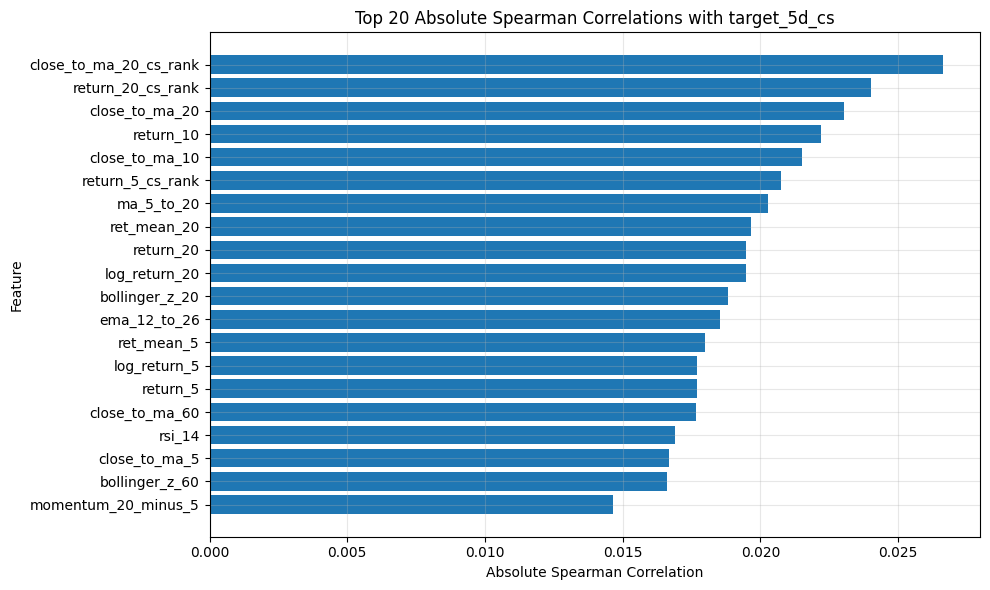

,year,feature,spearman_corr_with_target_5d_cs
0,2011,close_to_ma_20_cs_rank,-0.041219
1,2011,return_20_cs_rank,-0.013065
2,2011,close_to_ma_20,-0.016650
3,2011,return_10,-0.013649
4,2011,close_to_ma_10,-0.021183
...,...,...,...
115,2022,return_5_cs_rank,-0.020809
116,2022,ma_5_to_20,-0.041511
117,2022,ret_mean_20,-0.037292
118,2022,return_20,-0.036455


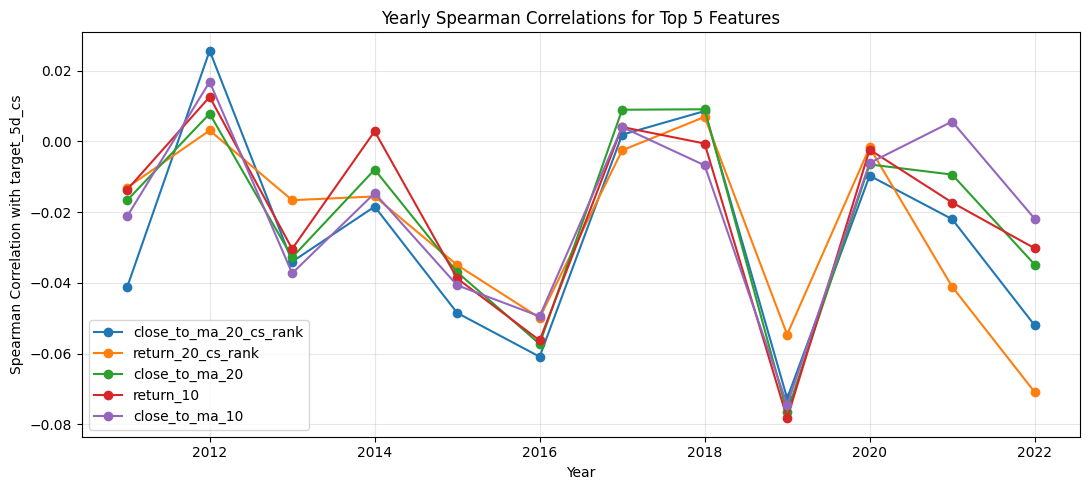

In [13]:
eda_top20_corr_df = eda_feature_target_corr_df.head(20).sort_values("abs_spearman", ascending=True)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(eda_top20_corr_df["feature"], eda_top20_corr_df["abs_spearman"])
ax.set_title("Top 20 Absolute Spearman Correlations with target_5d_cs")
ax.set_xlabel("Absolute Spearman Correlation")
ax.set_ylabel("Feature")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

eda_top10_features = eda_feature_target_corr_df["feature"].head(10).tolist()
eda_yearly_top_feature_corr_rows = []
for year, part in eda_df.groupby("year"):
    for feature in eda_top10_features:
        subset = part[[feature, "target_5d_cs"]].dropna()
        corr_value = subset[feature].corr(subset["target_5d_cs"], method="spearman") if not subset.empty else np.nan
        eda_yearly_top_feature_corr_rows.append({
            "year": year,
            "feature": feature,
            "spearman_corr_with_target_5d_cs": corr_value,
        })

eda_yearly_top_feature_corr_df = pd.DataFrame(eda_yearly_top_feature_corr_rows)
display(eda_yearly_top_feature_corr_df)

fig, ax = plt.subplots(figsize=(11, 5))
for feature in eda_top10_features[:5]:
    part = eda_yearly_top_feature_corr_df[eda_yearly_top_feature_corr_df["feature"] == feature]
    ax.plot(part["year"], part["spearman_corr_with_target_5d_cs"], marker="o", label=feature)
ax.set_title("Yearly Spearman Correlations for Top 5 Features")
ax.set_xlabel("Year")
ax.set_ylabel("Spearman Correlation with target_5d_cs")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


Individual feature-target correlations are usually weak, which is typical in stock-return prediction. The yearly lines also show that correlation strength can drift over time and sometimes even change sign.

That time variation is one of the clearest motivations for later using nonlinear models together with rolling-window validation instead of relying on a single full-sample linear relationship.


## 7. Feature Correlation and Redundancy

Many technical features are mechanically related because they share overlapping rolling windows or are transformations of similar price and volume histories.


In [14]:
eda_selected_features = []
eda_group_buckets = {
    "return/momentum": [],
    "volatility/risk": [],
    "volume/liquidity": [],
    "technical indicators": [],
    "other": [],
}
for _, row in eda_feature_target_corr_df.iterrows():
    group = eda_categorize_feature(row["feature"])
    eda_group_buckets[group].append(row["feature"])

for group in ["return/momentum", "volatility/risk", "volume/liquidity", "technical indicators", "other"]:
    eda_selected_features.extend(eda_group_buckets[group][:4])

for feature in eda_feature_target_corr_df["feature"]:
    if feature not in eda_selected_features:
        eda_selected_features.append(feature)
    if len(eda_selected_features) >= 20:
        break

eda_selected_features = eda_selected_features[:20]
eda_selected_feature_corr_df = eda_df[eda_selected_features].corr()
display(eda_selected_feature_corr_df)


,return_20_cs_rank,return_10,return_5_cs_rank,ret_mean_20,volume_1,log_volume_1,volume_zscore_60,relative_log_volume_60,close_to_ma_20_cs_rank,close_to_ma_20,close_to_ma_10,ma_5_to_20,close_1,low_1,high_1,open_1,return_20,log_return_20,bollinger_z_20,ema_12_to_26
return_20_cs_rank,1.000000,0.464169,0.435777,0.670239,0.033624,0.038957,0.040569,0.048112,0.818595,0.568279,0.391529,0.572167,0.020251,0.019625,0.019502,0.018829,0.666073,0.670423,0.504517,0.596029
return_10,0.464169,1.000000,0.437912,0.695869,0.011147,-0.001072,-0.038477,-0.003452,0.595907,0.910462,0.823352,0.841115,0.018846,0.018022,0.016359,0.015655,0.690830,0.689647,0.760955,0.606526
return_5_cs_rank,0.435777,0.437912,1.000000,0.311621,0.021245,0.033038,0.054018,0.059503,0.690037,0.483286,0.583515,0.319493,0.013648,0.012384,0.012328,0.010822,0.309166,0.311451,0.507567,0.213623
ret_mean_20,0.670239,0.695869,0.311621,1.000000,0.013750,-0.006632,-0.041730,-0.009375,0.570108,0.847106,0.592941,0.847585,0.026431,0.026117,0.024318,0.024238,0.994484,0.995288,0.672056,0.865427
volume_1,0.033624,0.011147,0.021245,0.013750,1.000000,0.513523,0.112894,0.098073,0.029813,0.012681,0.008457,0.011188,-0.081596,-0.081762,-0.081426,-0.081553,0.016911,0.012011,0.002663,0.018860
log_volume_1,0.038957,-0.001072,0.033038,-0.006632,0.513523,1.000000,0.197166,0.191354,0.040853,0.003809,0.003014,0.001231,-0.030433,-0.030417,-0.030342,-0.030354,0.000306,0.003451,0.011361,0.012162
volume_zscore_60,0.040569,-0.038477,0.054018,-0.041730,0.112894,0.197166,1.000000,0.939231,0.054030,-0.043660,-0.038061,-0.049856,0.000536,-0.001845,0.003127,0.000885,-0.032356,-0.050028,-0.075446,-0.037486
relative_log_volume_60,0.048112,-0.003452,0.059503,-0.009375,0.098073,0.191354,0.939231,1.000000,0.061127,-0.008335,-0.005667,-0.022623,-0.004922,-0.007045,-0.002656,-0.004678,0.000962,-0.022956,-0.054387,-0.012866
close_to_ma_20_cs_rank,0.818595,0.595907,0.690037,0.570108,0.029813,0.040853,0.054030,0.061127,1.000000,0.659172,0.555989,0.603546,0.021380,0.020322,0.020180,0.018980,0.566468,0.570245,0.623278,0.505356
close_to_ma_20,0.568279,0.910462,0.483286,0.847106,0.012681,0.003809,-0.043660,-0.008335,0.659172,1.000000,0.873920,0.893262,0.025819,0.024811,0.022721,0.021923,0.841326,0.845925,0.842154,0.728411


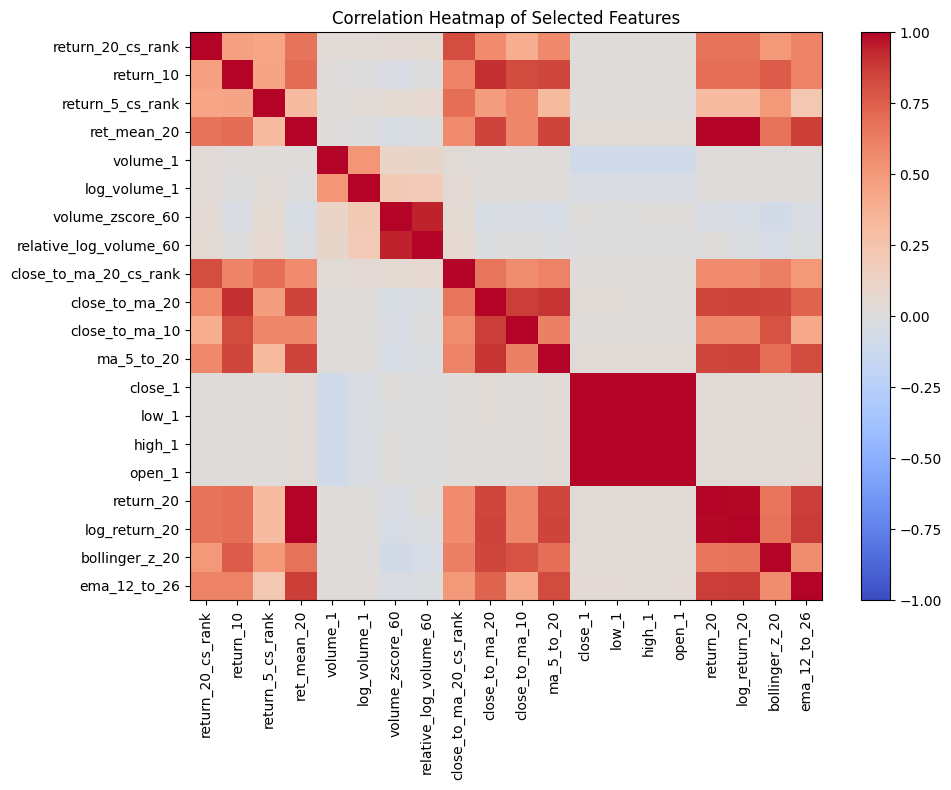

In [15]:
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(eda_selected_feature_corr_df.values, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
ax.set_title("Correlation Heatmap of Selected Features")
ax.set_xticks(range(len(eda_selected_features)))
ax.set_yticks(range(len(eda_selected_features)))
ax.set_xticklabels(eda_selected_features, rotation=90)
ax.set_yticklabels(eda_selected_features)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


Some features are strongly correlated because they encode related market behaviors over nearby horizons. That redundancy does not prevent LightGBM from being useful later, but it does mean that simple one-feature interpretations can be unstable or misleading.


## 8. Rolling Split Diagnostics

The final modeling notebook will use a 5-year rolling train window, 1-year validation window, and 1-year test window. These diagnostics verify the sample size and stock coverage available in each fold.


In [16]:
eda_rolling_fold_specs = [
    ("Fold 1", "2010-01-01", "2014-12-31", "2015-01-01", "2015-12-31", "2016-01-01", "2016-12-31"),
    ("Fold 2", "2011-01-01", "2015-12-31", "2016-01-01", "2016-12-31", "2017-01-01", "2017-12-31"),
    ("Fold 3", "2012-01-01", "2016-12-31", "2017-01-01", "2017-12-31", "2018-01-01", "2018-12-31"),
    ("Fold 4", "2013-01-01", "2017-12-31", "2018-01-01", "2018-12-31", "2019-01-01", "2019-12-31"),
    ("Fold 5", "2014-01-01", "2018-12-31", "2019-01-01", "2019-12-31", "2020-01-01", "2020-12-31"),
    ("Fold 6", "2015-01-01", "2019-12-31", "2020-01-01", "2020-12-31", "2021-01-01", "2021-12-31"),
    ("Fold 7", "2016-01-01", "2020-12-31", "2021-01-01", "2021-12-31", "2022-01-01", "2022-12-31"),
]

eda_rolling_split_rows = []
for fold_name, train_start, train_end, val_start, val_end, test_start, test_end in eda_rolling_fold_specs:
    train_part = eda_df[eda_df["date"].between(train_start, train_end)].copy()
    val_part = eda_df[eda_df["date"].between(val_start, val_end)].copy()
    test_part = eda_df[eda_df["date"].between(test_start, test_end)].copy()
    eda_rolling_split_rows.append({
        "Fold": fold_name,
        "Train Period": f"{train_start} to {train_end}",
        "Validation Period": f"{val_start} to {val_end}",
        "Test Period": f"{test_start} to {test_end}",
        "Number of Train Rows": len(train_part),
        "Number of Validation Rows": len(val_part),
        "Number of Test Rows": len(test_part),
        "Number of Train Stocks": train_part["code"].nunique(),
        "Number of Validation Stocks": val_part["code"].nunique(),
        "Number of Test Stocks": test_part["code"].nunique(),
    })

eda_rolling_split_diagnostics_df = pd.DataFrame(eda_rolling_split_rows)
display(eda_rolling_split_diagnostics_df)


,Fold,Train Period,Validation Period,Test Period,Number of Train Rows,Number of Validation Rows,Number of Test Rows,Number of Train Stocks,Number of Validation Stocks,Number of Test Stocks
0,Fold 1,2010-01-01 to 2014-12-31,2015-01-01 to 2015-12-31,2016-01-01 to 2016-12-31,43412,11075,11383,44,44,46
1,Fold 2,2011-01-01 to 2015-12-31,2016-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,54487,11383,11640,44,46,47
2,Fold 3,2012-01-01 to 2016-12-31,2017-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,55200,11640,11795,46,47,47
3,Fold 4,2013-01-01 to 2017-12-31,2018-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,56143,11795,11843,47,47,47
4,Fold 5,2014-01-01 to 2018-12-31,2019-01-01 to 2019-12-31,2020-01-01 to 2020-12-31,56975,11843,11891,47,47,47
5,Fold 6,2015-01-01 to 2019-12-31,2020-01-01 to 2020-12-31,2021-01-01 to 2021-12-31,57736,11891,11888,47,47,48
6,Fold 7,2016-01-01 to 2020-12-31,2021-01-01 to 2021-12-31,2022-01-01 to 2022-12-31,58552,11888,11602,47,48,49


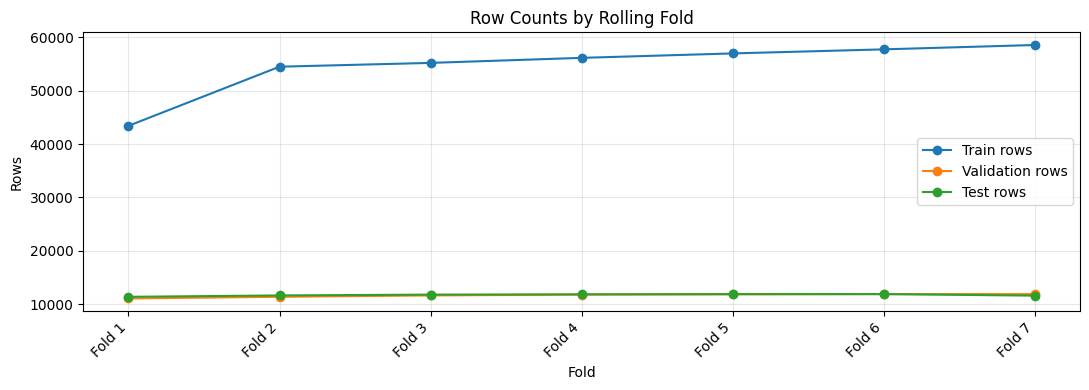

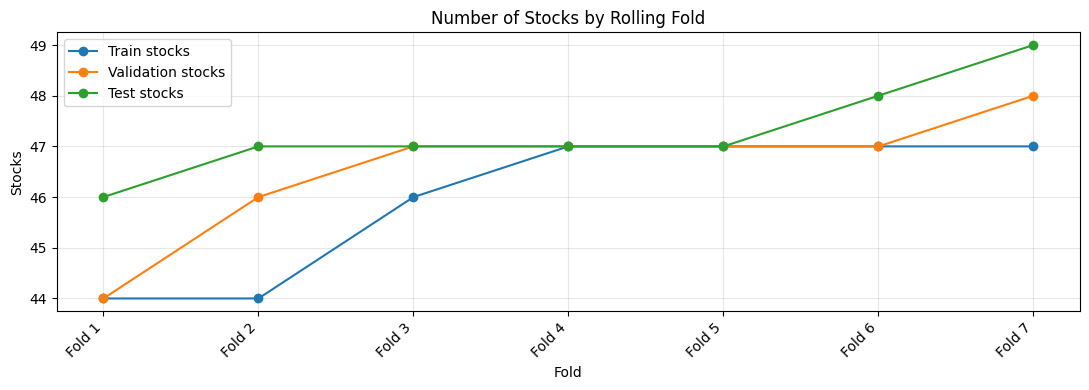

In [17]:
eda_fold_x = np.arange(len(eda_rolling_split_diagnostics_df))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(eda_fold_x, eda_rolling_split_diagnostics_df["Number of Train Rows"], marker="o", label="Train rows")
ax.plot(eda_fold_x, eda_rolling_split_diagnostics_df["Number of Validation Rows"], marker="o", label="Validation rows")
ax.plot(eda_fold_x, eda_rolling_split_diagnostics_df["Number of Test Rows"], marker="o", label="Test rows")
ax.set_title("Row Counts by Rolling Fold")
ax.set_xlabel("Fold")
ax.set_ylabel("Rows")
ax.set_xticks(eda_fold_x)
ax.set_xticklabels(eda_rolling_split_diagnostics_df["Fold"], rotation=45, ha="right")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(eda_fold_x, eda_rolling_split_diagnostics_df["Number of Train Stocks"], marker="o", label="Train stocks")
ax.plot(eda_fold_x, eda_rolling_split_diagnostics_df["Number of Validation Stocks"], marker="o", label="Validation stocks")
ax.plot(eda_fold_x, eda_rolling_split_diagnostics_df["Number of Test Stocks"], marker="o", label="Test stocks")
ax.set_title("Number of Stocks by Rolling Fold")
ax.set_xlabel("Fold")
ax.set_ylabel("Stocks")
ax.set_xticks(eda_fold_x)
ax.set_xticklabels(eda_rolling_split_diagnostics_df["Fold"], rotation=45, ha="right")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


Each fold uses only past data for training and reserves the later validation and test years for model selection and final out-of-sample evaluation. This rolling design is more appropriate for non-stationary financial data than a single static split because it respects chronology and reveals how sample conditions evolve through time.


## 9. Equal-Weight Market Proxy

Before any ML modeling, it is useful to inspect a simple equal-weight forward-return proxy for the universe. This is not a backtest of a strategy; it is just a descriptive benchmark for the market environment faced by the later ranking model.


In [18]:
eda_equal_weight_proxy_df = (
    eda_df.groupby("date")
    .agg(equal_weight_forward_return=("target_5d_raw", "mean"))
    .reset_index()
    .sort_values("date")
    .reset_index(drop=True)
)
eda_equal_weight_proxy_df["proxy_equity"] = (1 + eda_equal_weight_proxy_df["equal_weight_forward_return"]).cumprod()
eda_equal_weight_proxy_df["proxy_cumulative_return"] = eda_equal_weight_proxy_df["proxy_equity"] - 1
eda_equal_weight_proxy_df["year"] = eda_equal_weight_proxy_df["date"].dt.year

eda_market_proxy_by_year_df = (
    eda_equal_weight_proxy_df.groupby("year")
    .agg(
        mean_equal_weight_forward_return=("equal_weight_forward_return", "mean"),
        std_equal_weight_forward_return=("equal_weight_forward_return", "std"),
        approximate_cumulative_return=("equal_weight_forward_return", lambda x: (1 + pd.Series(x)).prod() - 1),
        num_dates=("date", "size"),
    )
    .reset_index()
)

display(eda_equal_weight_proxy_df)
display(eda_market_proxy_by_year_df)


,date,equal_weight_forward_return,proxy_equity,proxy_cumulative_return,year
0,2011-01-03,0.019144,1.019144,0.019144,2011
1,2011-01-04,0.028910,1.048608,0.048608,2011
2,2011-01-05,0.047510,1.098427,0.098427,2011
3,2011-01-06,0.044511,1.147320,0.147320,2011
4,2011-01-07,0.063271,1.219913,0.219913,2011
...,...,...,...,...,...
3005,2022-12-09,-0.029474,145629.993883,145628.993883,2022
3006,2022-12-12,-0.063815,136336.594990,136335.594990,2022
3007,2022-12-13,-0.078970,125570.099928,125569.099928,2022
3008,2022-12-14,-0.046156,119774.270555,119773.270555,2022


,year,mean_equal_weight_forward_return,std_equal_weight_forward_return,approximate_cumulative_return,num_dates
0,2011,-0.000263,0.046667,-0.289077,252
1,2012,0.002140,0.030655,0.518203,250
2,2013,0.007723,0.019743,5.620869,252
3,2014,0.004724,0.026918,1.993727,252
4,2015,0.000188,0.027997,-0.051058,252
5,2016,0.008399,0.028393,6.442760,252
6,2017,0.007966,0.021347,5.923501,251
7,2018,-0.002696,0.036210,-0.570032,251
8,2019,0.011162,0.030392,13.629660,252
9,2020,0.010752,0.053752,9.379010,253


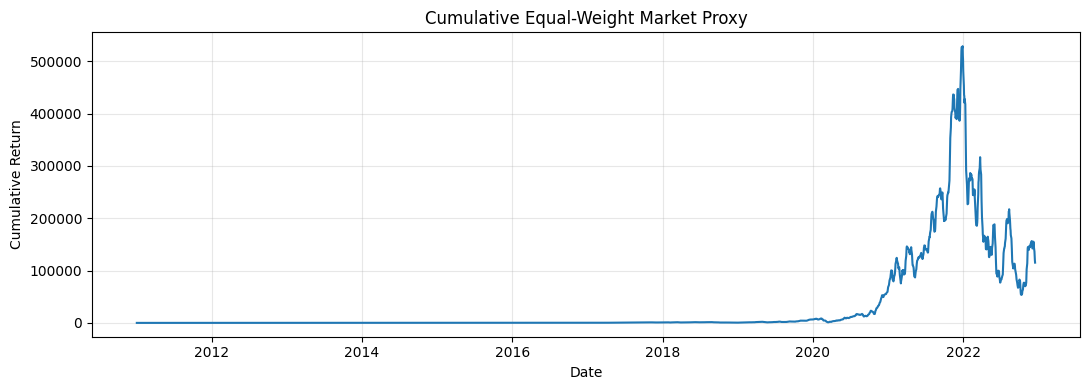

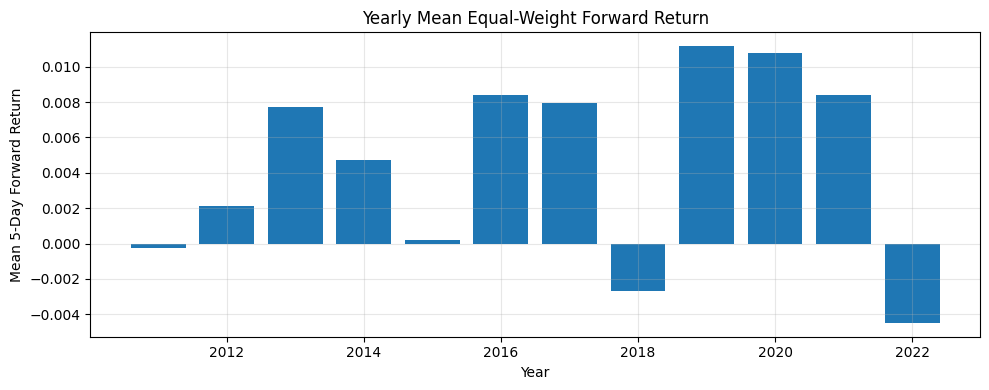

In [19]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(eda_equal_weight_proxy_df["date"], eda_equal_weight_proxy_df["proxy_cumulative_return"], linewidth=1.5)
ax.set_title("Cumulative Equal-Weight Market Proxy")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Return")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(eda_market_proxy_by_year_df["year"], eda_market_proxy_by_year_df["mean_equal_weight_forward_return"])
ax.set_title("Yearly Mean Equal-Weight Forward Return")
ax.set_xlabel("Year")
ax.set_ylabel("Mean 5-Day Forward Return")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Market conditions differ materially across years, which means any later predictive model will face changing background environments. A cross-sectional long-short framework should therefore not rely on market direction alone, and that further supports the use of cross-sectionally demeaned targets.


## 10. EDA Takeaways

1. Dataset coverage is broad and the stock universe is mostly stable, though the panel is mildly unbalanced.
2. The target distribution is noisy and heavy-tailed rather than cleanly Gaussian.
3. Cross-sectional dispersion across stocks creates potential opportunity for ranking-based strategies.
4. Individual feature-target correlations are weak and can vary over time.
5. These patterns motivate a rolling-window LightGBM model and strict out-of-sample long-short portfolio evaluation.


In [20]:
print("EDA notebook completed successfully.")


EDA notebook completed successfully.
